# Praktikum 1
SVM dengan Data Dummy Linier

**Support Vector Machine (SVM)** adalah classifier yang mencari **hyperplane** (garis pemisah) terbaik antara dua kelas. "Terbaik" di sini bukan sekadar garis yang bisa memisahkan, tetapi garis yang **margin**-nya paling lebar — jarak antara garis dengan titik data terdekat dari masing-masing kelas.

* Titik data terdekat dengan garis pemisah disebut **support vector**. Hanya titik inilah yang menentukan posisi garis; titik lain yang sudah jauh di area benar tidak berpengaruh.
* **Hard margin** menuntut semua titik terklasifikasi benar tanpa pelanggaran. Pendekatan ini hanya masuk akal bila data benar-benar terpisah, seperti data dummy pada praktikum ini.
* Pendekatan *large margin* membuat model lebih tahan terhadap noise dan lebih baik dalam generalisasi.

Data yang dipakai adalah data dummy 2 dimensi hasil `make_blobs`: 50 titik, 2 pusat kelas, dengan `cluster_std` kecil sehingga kedua kelas terpisah jelas.

### Langkah 1 - Import Library

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import seaborn as sns

sns.set(style='whitegrid')

### Langkah 2 - Membuat Data Dummy
Dua kelas dibangkitkan dengan `cluster_std=0.60` agar keduanya terpisah secara linier.

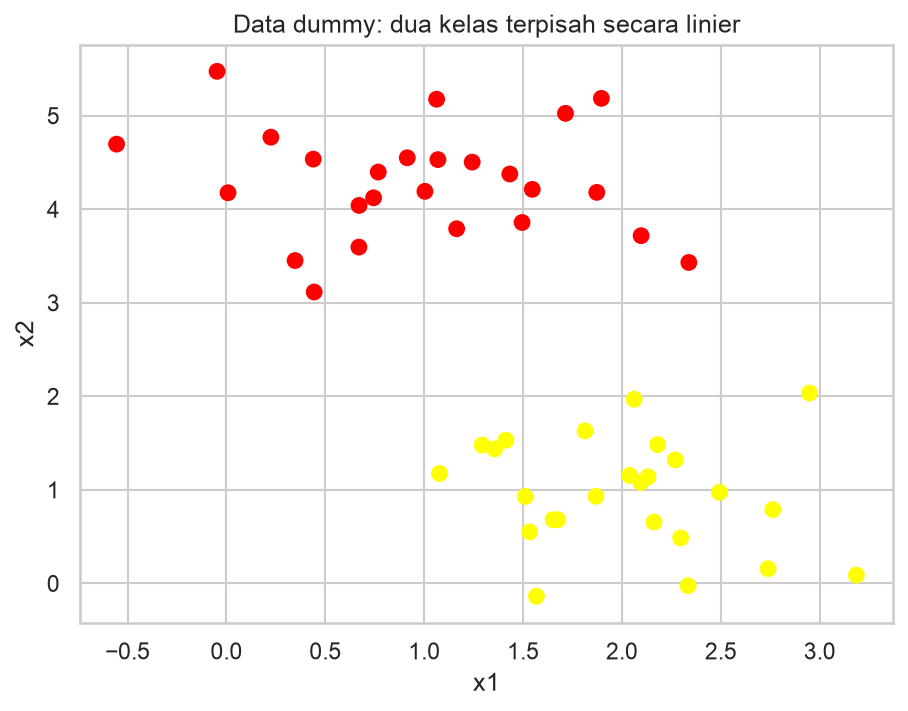

Dimensi X: (50, 2) | jumlah tiap kelas: [25 25]


In [2]:
from sklearn.datasets import make_blobs

X, y = make_blobs(n_samples=50, centers=2,
                  random_state=0, cluster_std=0.60)

plt.figure(figsize=(7, 5))
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
plt.title('Data dummy: dua kelas terpisah secara linier')
plt.xlabel('x1')
plt.ylabel('x2')
plt.show()

print('Dimensi X:', X.shape, '| jumlah tiap kelas:', np.bincount(y))

### Langkah 3 - Ilustrasi Garis Pemisah
Untuk membuat model klasifikasi, dibutuhkan garis pemisah antara dua himpunan data. Persoalannya: banyak garis **bisa** memisahkan keduanya. Titik baru `x` (tanda biru) pada posisi tertentu membuat pilihan garis menjadi penting — garis mana yang dipilih menentukan label titik baru itu.

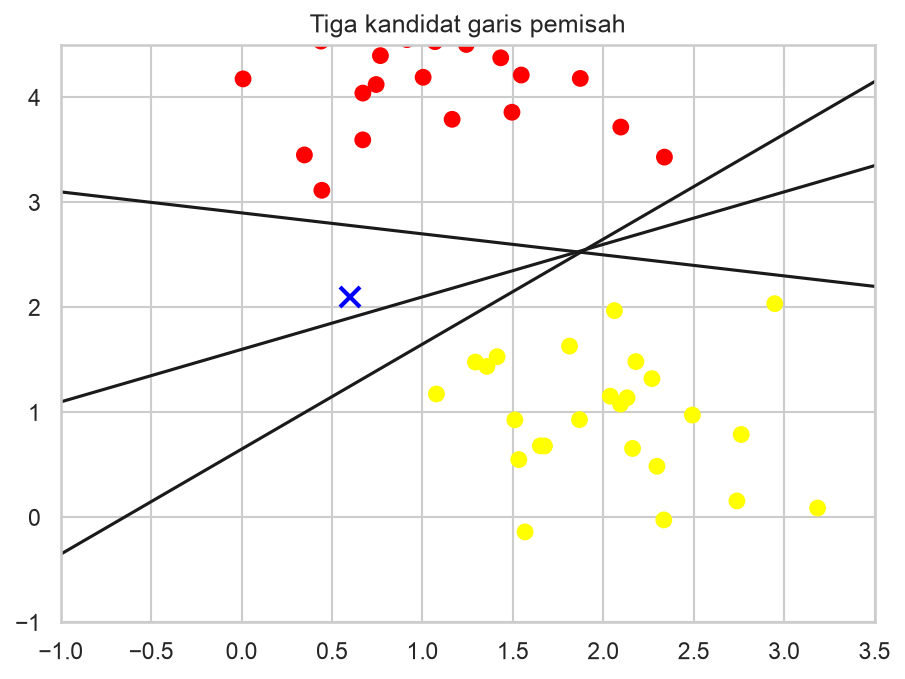

In [3]:
xfit = np.linspace(-1, 3.5)

plt.figure(figsize=(7, 5))
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')

# Data baru 'x' yang belum diketahui labelnya
plt.plot([0.6], [2.1], 'x', color='blue', markeredgewidth=2, markersize=10)

# Tiga kandidat garis pemisah
for m, b in [(1, 0.65), (0.5, 1.6), (-0.2, 2.9)]:
    plt.plot(xfit, m * xfit + b, '-k')

plt.xlim(-1, 3.5)
plt.ylim(-1, 4.5)
plt.title('Tiga kandidat garis pemisah')
plt.show()

Ketiga garis sama-sama "benar" memisahkan kedua kelas, tetapi memberi keputusan berbeda untuk titik `x`. SVM menjawab kebingungan ini dengan aturan **margin terlebar**.

### Langkah 4 - Ilustrasi Margin
Margin digambarkan sebagai pita di sekitar garis. Garis dengan pita yang lebih lebar memberi ruang aman lebih besar terhadap variasi data.

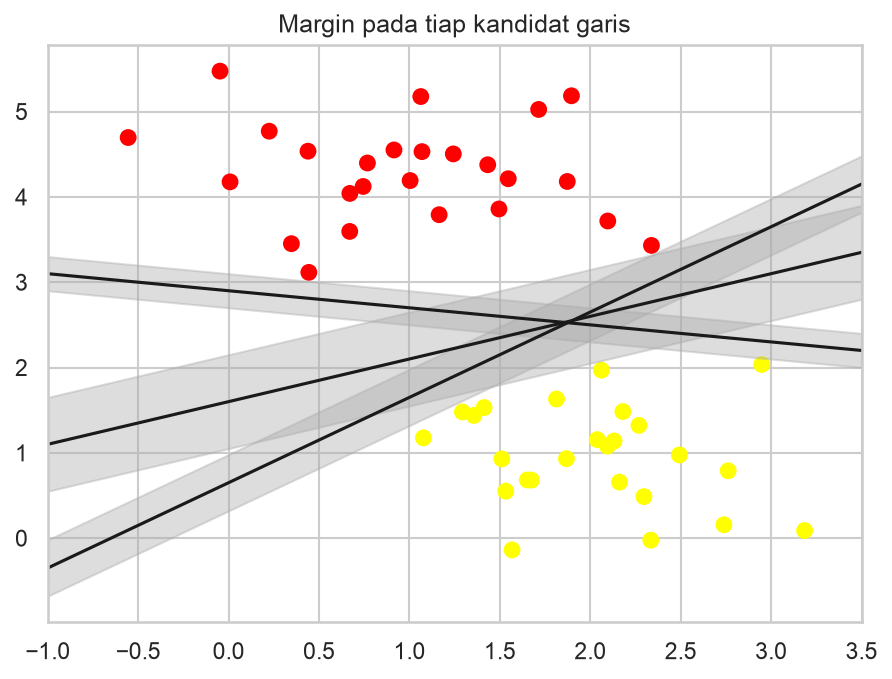

In [4]:
xfit = np.linspace(-1, 3.5)

plt.figure(figsize=(7, 5))
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')

for m, b, d in [(1, 0.65, 0.33), (0.5, 1.6, 0.55), (-0.2, 2.9, 0.2)]:
    yfit = m * xfit + b
    plt.plot(xfit, yfit, '-k')
    plt.fill_between(xfit, yfit - d, yfit + d, edgecolor='none',
                     color='#AAAAAA', alpha=0.4)

plt.xlim(-1, 3.5)
plt.title('Margin pada tiap kandidat garis')
plt.show()

### Langkah 5 - Fitting Model
Model SVM dilatih dengan **kernel linear** dan `C` sangat besar (`1E10`) untuk meniru *hard margin*: pelanggaran margin diberi penalti ekstrem sehingga hampir tidak ditoleransi.

In [5]:
from sklearn.svm import SVC

model = SVC(kernel='linear', C=1E10)
model.fit(X, y)

print('Jumlah support vector:', model.n_support_)

Jumlah support vector: [2 1]


Selanjutnya dibuat fungsi bantu untuk memvisualisasikan hyperplane, margin, dan support vector hasil fit.

In [6]:
def plot_svc_decision_function(model, ax=None, plot_support=True):
    if ax is None:
        ax = plt.gca()
    xlim = ax.get_xlim()
    ylim = ax.get_ylim()

    # Buat grid untuk evaluasi model
    x = np.linspace(xlim[0], xlim[1], 30)
    y = np.linspace(ylim[0], ylim[1], 30)
    Y, X = np.meshgrid(y, x)
    xy = np.vstack([X.ravel(), Y.ravel()]).T
    P = model.decision_function(xy).reshape(X.shape)

    # Plot batas keputusan dan margin
    ax.contour(X, Y, P, colors='k',
               levels=[-1, 0, 1], alpha=0.5,
               linestyles=['--', '-', '--'])

    # Plot support vector
    if plot_support:
        ax.scatter(model.support_vectors_[:, 0],
                   model.support_vectors_[:, 1],
                   s=300, linewidth=1, facecolors='none')
    ax.set_xlim(xlim)
    ax.set_ylim(ylim)

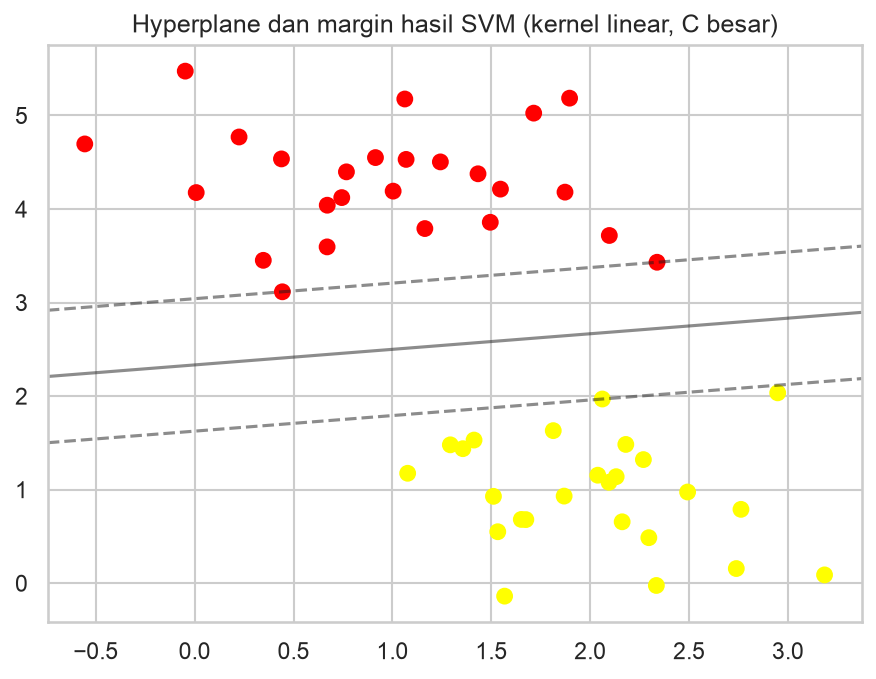

In [7]:
plt.figure(figsize=(7, 5))
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
plot_svc_decision_function(model)
plt.title('Hyperplane dan margin hasil SVM (kernel linear, C besar)')
plt.show()

Garis tegas di tengah adalah hyperplane, dua garis putus-putus adalah batas margin, dan lingkaran besar menandai **support vector** — titik yang menyentuh margin.

In [8]:
model.support_vectors_

array([[0.44359863, 3.11530945],
       [2.33812285, 3.43116792],
       [2.06156753, 1.96918596]])

Fitting SVM sepenuhnya ditentukan oleh posisi support vector. Titik-titik yang jauh dari margin dan sudah berada di area yang benar **tidak** memengaruhi loss function, sehingga tidak bisa mengubah garis. Untuk membuktikannya, model dilatih ulang dengan jumlah data berbeda (60 dan 120 titik).

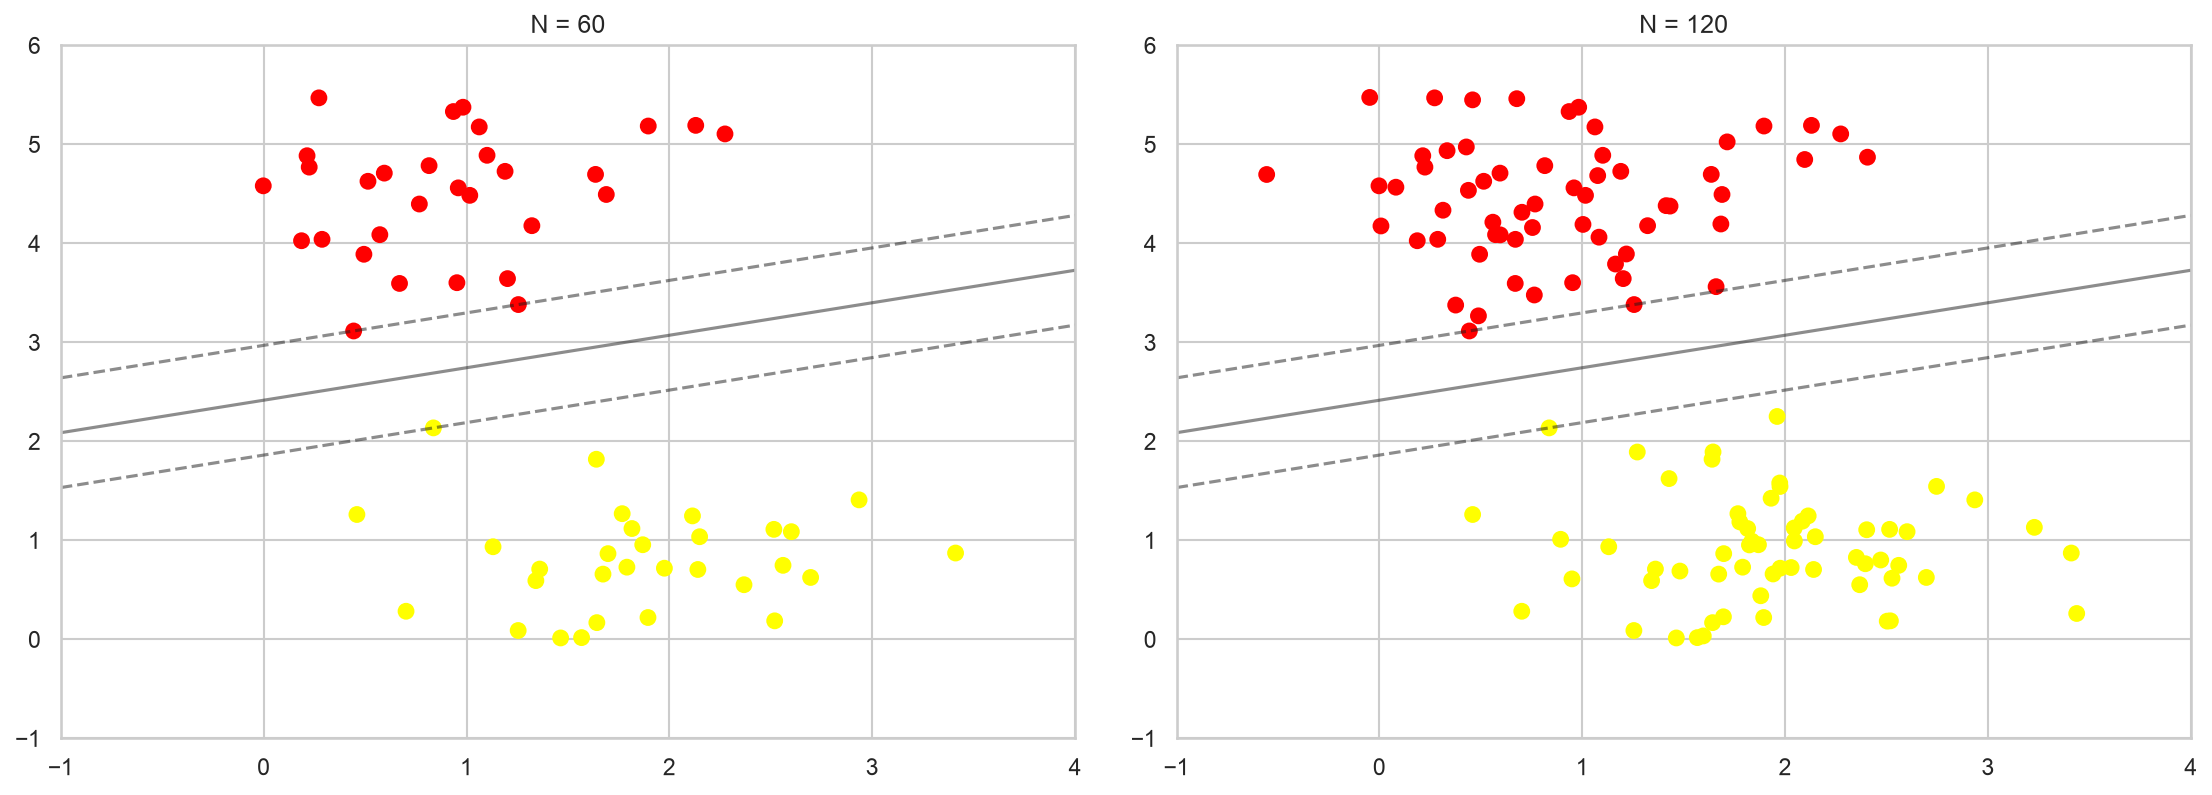

In [9]:
def plot_svm(N=10, ax=None):
    X, y = make_blobs(n_samples=200, centers=2,
                      random_state=0, cluster_std=0.60)
    X = X[:N]
    y = y[:N]

    model = SVC(kernel='linear', C=1E10)
    model.fit(X, y)

    ax = ax or plt.gca()
    ax.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
    ax.set_xlim(-1, 4)
    ax.set_ylim(-1, 6)
    plot_svc_decision_function(model, ax)

fig, ax = plt.subplots(1, 2, figsize=(16, 6))
fig.subplots_adjust(left=0.0625, right=0.95, wspace=0.1)
for axi, N in zip(ax, [60, 120]):
    plot_svm(N, axi)
    axi.set_title('N = {0}'.format(N))
plt.show()

> **Penyesuaian:** modul memakai `interact(plot_svm, N=[10, 200], ...)` dari `ipywidgets`. Lingkungan praktikum ini tidak memuat `ipywidgets`, sehingga interaksi diganti dua panel statis (`N = 60` dan `N = 120`). Silakan jalankan versi `interact` bila `ipywidgets` tersedia:
>
> ```python
> from ipywidgets import interact, fixed
> interact(plot_svm, N=[10, 200], ax=fixed(None))
> ```

In [10]:
# Rekap jumlah support vector untuk beberapa ukuran data
X_all, y_all = make_blobs(n_samples=200, centers=2,
                          random_state=0, cluster_std=0.60)

baris = []
for N in [10, 30, 60, 120, 200]:
    m = SVC(kernel='linear', C=1E10).fit(X_all[:N], y_all[:N])
    baris.append({
        'N (jumlah data)': N,
        'Jumlah support vector': int(m.n_support_.sum()),
        'Akurasi latih': m.score(X_all[:N], y_all[:N]),
    })

pd.DataFrame(baris)

,N (jumlah data),Jumlah support vector,Akurasi latih
0,10,2,1.0
1,30,3,1.0
2,60,3,1.0
3,120,3,1.0
4,200,3,1.0


In [11]:
# Bukti bahwa hanya support vector yang menentukan hyperplane:
# model dilatih ulang HANYA dengan titik-titik support vector
sv = model.support_
model_sv = SVC(kernel='linear', C=1E10).fit(X[sv], y[sv])

print(f'Support vector: {len(sv)} dari {len(X)} titik')
print('Koefisien (semua data):', model.coef_.round(3), '| b =', model.intercept_.round(3))
print('Koefisien (hanya SV)  :', model_sv.coef_.round(3), '| b =', model_sv.intercept_.round(3))

grid = np.array([[a, b] for a in np.linspace(-1, 4, 5) for b in np.linspace(-1, 4, 5)])
selisih = np.abs(model.decision_function(grid) - model_sv.decision_function(grid)).max()
print(f'Selisih maksimum decision_function: {selisih:.2e}')

Support vector: 3 dari 50 titik
Koefisien (semua data): [[ 0.235 -1.413]] | b = [3.296]
Koefisien (hanya SV)  : [[ 0.235 -1.412]] | b = [3.295]
Selisih maksimum decision_function: 1.43e-03


Meski hanya dilatih dengan 3 dari 50 titik, model menghasilkan hyperplane yang sama. Selisih yang tersisa (orde $10^{-3}$) murni berasal dari toleransi numerik solver libsvm saat `C` sangat besar, bukan perbedaan model.

### Kesimpulan

* SVM tidak memilih sembarang garis pemisah; ia memilih garis dengan **margin terlebar**, sehingga titik baru di sekitar batas keputusan tidak mudah berubah label.
* Hanya **support vector** yang menentukan hyperplane. Melatih ulang model dengan 3 support vector saja (dari 50 titik) menghasilkan garis yang sama — sisanya tidak berkontribusi pada loss function.
* Nilai `C` besar (`1E10`) meniru *hard margin*: semua titik dipaksa berada di sisi benar dan tidak ada peluang melanggar margin.
* Konsekuensinya, *hard margin* hanya cocok untuk data yang benar-benar terpisah. Ketika data tumpang tindih (Praktikum 3), nilai `C` harus diperkecil agar model mau berkompromi.